# Monochrome camera calibration
One of the great disadvantages with using lenses is the distortion it introduces to the image. For vacation images, this is usually not a problem, but when we use the image to describe the physical surroundings it becomes important that the images are representative of the scene it captures. An easy way to get an indication of how distorted an image is by looking at what is supposed to be straight lines since they will appear curved. The following exercises you will be calibrating a camera to obtain a camera matrix such that you can undistort images from this camera.

In [1]:
import glob

import cv2
import matplotlib.pyplot as plt
import numpy as np

## Exercise 1
The process of calibrating an image consists of mainly 3 steps: 1) find chessboard-corners in a dataset of images containing a chessboard. 2) Use the corner points to compute a camera matrix. 3) Use the camera matrix to undistort images.

After setting some optimization parameters we can loop over all the images in the `imgs` folder and extract the checkerboard corners.

Use any of the images in the folder `imgs` to extract the number of checkerboard corners there are on the checkerboard. Fill in the information in `nb_vertical` and `nb_horizontal` and look up the opencv [findChessboardCorners](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html#ga93efa9b0aa890de240ca32b11253dd4a) function and implement it in the below code snippet .

In [ ]:
# A chessboard pattern has corners at known, evenly-spaced positions. Since we
# know where these corners should be in 3D, we can compare that to where they
# actually appear in each image to work out how the lens distorted the picture.
# How the object points (objp) are built: objp represents the chessboard's
# corners in an idealized 3D coordinate system, with Z always 0 (the board is
# flat) and X/Y set to simple integer grid positions (0, 0, 0), (1, 0, 0),
# (2, 0, 0)... one entry per corner. This is the "ground truth" layout every
# detected image will be compared against.
# Why we need nb_vertical/nb_horizontal to be exactly right: These describe the
# number of internal corners (where black and white squares meet) along each
# axis of the physical checkerboard used. If this doesn't exactly match the real
# board, findChessboardCorners will simply fail to detect anything (ret == False)
# in every image.
# Main loop:
#   - For each image, convert to grayscale since corner detection works on
#     intensity, not color.
#   - cv2.findChessboardCorners(img, (nb_vertical, nb_horizontal), None) searches
#     for a chessboard pattern with exactly that many internal corners for
#     pattern of the given size; it returns whether the search succeeded (ret)
#     and, if so, the detected 2D pixel positions of each corner.
#   - Successful detections have their known 3D layout (objp) and detected 2D
#     pixel positions (corners) appended to objpoints/imgpoints respectively.
#     Building up matched (3D real-world point, 2D pixel position) pairs across
#     all calibration images, which is exactly what cv2.calibrateCamera() needs
#     as input below.
#   - cv2.drawChessboardCorners() overlays the detected corners on the image for
#     image for a visual sanity check, and cv2.imshow()/waitKey(50) displays
#     each one in turn (50ms per image) so you can watch detection succeed/fail
#     across the dataset as the loop runs.
# Note: 'ret == True' is identical to just writing 'if ret:'.
nb_vertical = 6
nb_horizontal = 7

# Prepare object points, like (0, 0, 0), (1, 0, 0), (2, 0, 0) ....,(6, 5, 0).
objp = np.zeros((nb_horizontal * nb_vertical, 3), np.float32)
objp[:, :2] = np.mgrid[0:nb_vertical, 0:nb_horizontal].T.reshape(-1, 2)

# Arrays to store object points and image points from all the images.
objpoints = []  # 3D point in real world space.
imgpoints = []  # 2D points in image plane.

images = glob.glob("imgs/*.png")
assert images

for fname in images:
    img = cv2.imread(fname)
    h, w = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    ret, corners = cv2.findChessboardCorners(
        img, (nb_vertical, nb_horizontal), None
    )

    # If found, add object points, image points (after refining them).
    if ret == True:
        objpoints.append(objp)

        imgpoints.append(corners)

        # Draw and display the corners.
        img = cv2.drawChessboardCorners(
            img, (nb_vertical, nb_horizontal), corners, ret
        )
        cv2.imshow("img", img)
        cv2.waitKey(50)

cv2.destroyAllWindows()

Using the extracted corners we can obtain a camera matrix that contains the information needed to undistort images

In [3]:
# Why cv2.calibrateCamera(): given many (3D real-world point, 2D pixel position)
# pairs collected from multiple images/angles of the same physical chessboard,
# this function solves for the camera's internal geometry. Most importantly the
# camera matrix (focal length + optical center) and distortion coefficients
# (how the lens bends light, especially near the edges of the frame) that best
# explain how those 3D points ended up projected to their observed 2D pixel
# positions. What it returns:
#   ret: the overall re-projection error (how well the computed model explains
#     the detected corners; lower is better).
#   mtx: the 3x3 camera matrix.
#   dist: the lens distortion coefficients.
#   rvecs/tvecs: the rotation/translation of the chessboard relative to the
#     camera, estimated separately for each calibration image.
# cv2.calibrateCamera() expects the image size as (width, height), but gray.shape
# gives (height, width). Reversing it with [::-1] fixes the ordering, using
# whichever image was last processed in the previous loop as a stand-in for the
# image size (all calibration images are assumed to share the same resolution).
# Why getOptimalNewCameraMatrix(): the raw camera matrix computed above is only
# strictly valid over the region actually covered by the calibration images;
# this function computes a refined camera matrix tailored to a specific target
# image size, along with a region of interest (roi) marking which part of the
# undistorted output will contain valid (non-black) pixels. The scaling parameter
# (1 here) controls how much of the original image is retained vs. how many
# black border pixels are introduced when undistorting; 1 keeps all original
# pixels (at the cost of more black border), 0 would crop to only valid pixels.
ret, mtx, dist, rvecs, tvecs = cv2.calibrateCamera(
    objpoints, imgpoints, gray.shape[::-1], None, None
)
img = cv2.imread("imgs/1403709067387836928.png")
h, w = img.shape[:2]
newcameramtx, roi = cv2.getOptimalNewCameraMatrix(mtx, dist, (w, h), 1, (w, h))

In [4]:
# Inspect the refined camera matrix computed for the target image size.
print("New camera matrix:")
print(newcameramtx)

# Inspect the raw camera matrix returned directly by calibrateCamera(). The two
# matrices are related but not identical. This one describes the camera's
# intrinsic geometry in general, while the refined version above is adjusted
# for the chosen output image size/cropping behavior.
print("Camera matrix:")
print(mtx)

# Inspect the lens distortion coefficients found during calibration. This set
# of numbers captures how much the lens bends light. Primarily radial distortion
# (things appear to bulge or pinch, especially near the image edges; "barrel"
# or "pincushion" distortion) and a smaller tangential distortion (from the
# lens not being perfectly parallel to the image sensor).
print("Distortion coefficients:")
print(dist)

New camera matrix:
[[293.81095294   0.         339.76510121]
 [  0.         285.8501061  254.95301191]
 [  0.           0.           1.        ]]
Camera matrix:
[[459.6226712    0.         362.25100099]
 [  0.         458.51170429 246.59100825]
 [  0.           0.           1.        ]]
Distortion coefficients:
[[-3.13516387e-01  1.32792351e-01  2.83146266e-04  3.10036271e-04
  -2.92398139e-02]]


The last step is to actually undistort an image:

Text(0.5, 1.0, 'Undistorted image')

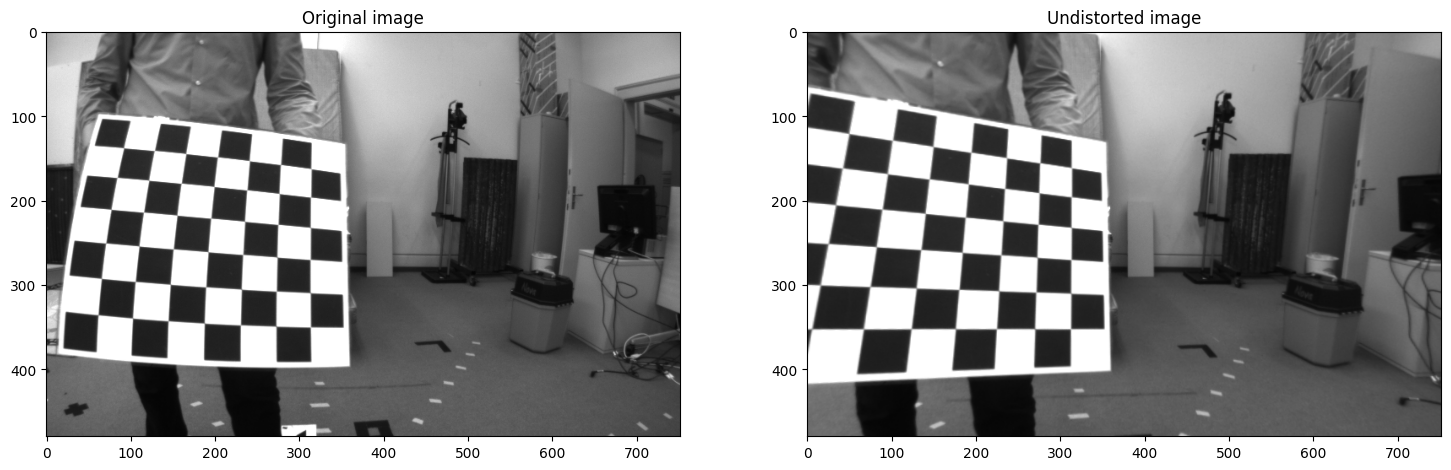

In [5]:
# Undistort a sample image using the calibration results, and compare it side
# by side with the original. Given the camera matrix and distortion coefficients
# computed above, cv2.undistort() can now correct any image taken with this same
# camera/lens combination, warping it back so that lines that should be straight
# in the real world actually appear straight in the image.
# Why img[..., [2, 1, 0]]: this reorders the last axis (color channels) of the array
# from OpenCV's native BGR order to RGB order for correct display in matplotlib.
dst = cv2.undistort(img, mtx, dist, None, None)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 18))
ax[0].imshow(img[..., [2, 1, 0]])
ax[0].set_title("Original image")
ax[1].imshow(dst[..., [2, 1, 0]])
ax[1].set_title("Undistorted image")

A refining step can be to crop the image such that it doesn't contain the large black areas at the edges of the image.

(47, 85, 619, 328)


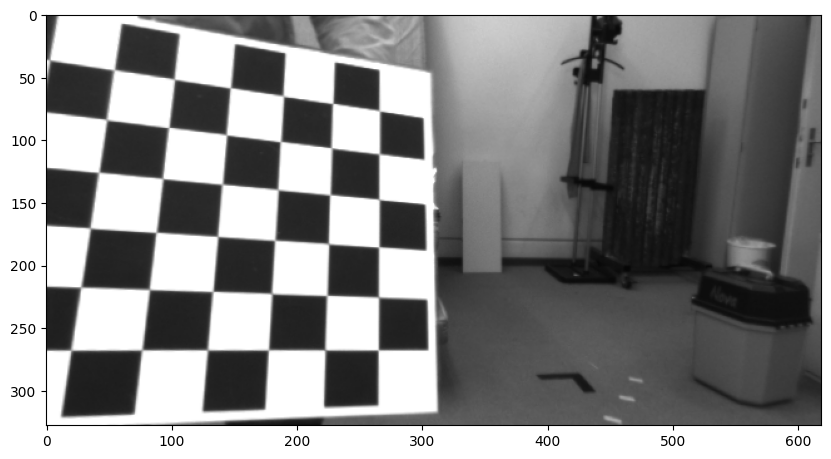

In [6]:
# Crop the undistorted image down to only its valid (non-black) region.
# Undistorting an image can leave black, empty padding around parts of the
# frame where the correction pushed pixels outside the original image bounds
# (most visible near the edges/corners). The 'roi' returned earlier by
# getOptimalNewCameraMatrix() marks which rectangular sub-region contains only
# valid pixel data. roi is unpacked into its (x, y, width, height) components,
# and standard numpy slicing crops the undistorted image down to just that
# region, discarding the invalid black border areas around it.
print(roi)
x, y, w, h = roi
dst = dst[y : y + h, x : x + w]
plt.figure(figsize=(10, 10))
plt.imshow(dst[..., [2, 1, 0]])